# Empirical distribution function with confidence bands

We simulate a sample from a standard normal distribution, look at its histogram, and estimate its distribution function with the empirical distribution function. Then we build a confidence band for the whole distribution function with the Dvoretzky-Kiefer-Wolfowitz inequality, and check by simulation how often the band contains the true distribution function.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import norm
from statsmodels.distributions import ECDF
from ipywidgets import interact, IntSlider, FloatSlider

In [2]:
SEED = 0      # Seed of the random number generator
ALPHA = 0.05  # Level of significance of the confidence band

In [3]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
opt_color   = '#E69F00'

## A sample from the standard normal distribution

We simulate $n=1000$ observations from a standard normal distribution, and calculate their mean and standard deviation.

In [4]:
rng = np.random.default_rng(SEED)

n = 1000
x = rng.normal(size=n)

In [5]:
print(np.mean(x))
print(np.std(x))

-0.04802827676298692
0.9767529623571052


The number of bins of the histogram is given by Sturges' rule, $\lceil \log_2 n\rceil + 1$.

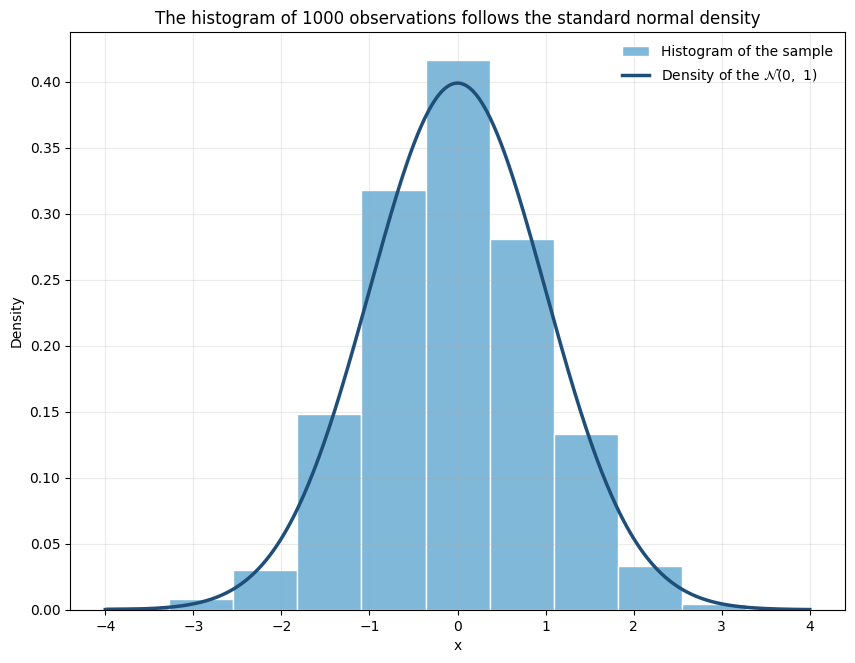

In [6]:
grid = np.linspace(-4, 4, 400)

plt.figure(figsize=(10, 7.5))
plt.hist(x, bins=int(np.ceil(np.log2(n)))+1, range=(-4, 4), density=True,
         color=ci_color, edgecolor='white', label='Histogram of the sample')
plt.plot(grid, norm.pdf(grid), color=line_color, lw=2.5, label=r'Density of the $\mathcal{N}(0,\ 1)$')

plt.xlabel('x')
plt.ylabel('Density')
plt.title(f'The histogram of {n} observations follows the standard normal density')
plt.legend(frameon=False)
plt.grid(True, alpha=0.25)

## Empirical distribution function and its confidence band

The empirical distribution function of a sample $X_1,\ldots,X_n$ with distribution function $F$ is

$$
\hat F_n(x) = \frac{1}{n}\sum_{i=1}^n 1_{X_i\leq x}.
$$

The Dvoretzky-Kiefer-Wolfowitz inequality bounds the largest distance between $\hat F_n$ and $F$,

$$
\mathbb{P}\left(\sup_x\left|\hat F_n(x)-F(x)\right|>\varepsilon\right)\leq 2e^{-2n\varepsilon^2}.
$$

Making the right side equal to $\alpha$ we get $\varepsilon_n=\sqrt{\frac{1}{2n}\log\frac{2}{\alpha}}$, and the functions

$$
L(x)=\max\left\{\hat F_n(x)-\varepsilon_n,\ 0\right\},\qquad U(x)=\min\left\{\hat F_n(x)+\varepsilon_n,\ 1\right\}
$$

form a confidence band: $L(x)\leq F(x)\leq U(x)$ for every $x$ at the same time, with probability at least $1-\alpha$.

In [7]:
def dkw_epsilon(n, alpha):
    return np.sqrt(np.log(2/alpha) / (2*n))

def upper_band(sample, alpha):
    ecdf = ECDF(sample)
    return np.minimum(ecdf.y + dkw_epsilon(len(sample), alpha), 1)

def lower_band(sample, alpha):
    ecdf = ECDF(sample)
    return np.maximum(ecdf.y - dkw_epsilon(len(sample), alpha), 0)

Function to plot the empirical distribution function, its confidence band, and the true distribution function. The short red lines at the bottom are the observations.

In [8]:
def plot_band(ax, sample, alpha, x1=-4, x2=4, legend=True):
    ecdf = ECDF(sample)

    # The first value of ecdf.x is -inf. We extend the steps to both ends of the plot
    xs = np.append(ecdf.x, max(x2, sample.max()+1))
    xs[0] = min(x1, sample.min()-1)
    extend = lambda y: np.append(y, y[-1])

    ax.fill_between(xs, extend(lower_band(sample, alpha)), extend(upper_band(sample, alpha)), step='post',
                    color=ci_color, alpha=0.7, label=f'{1-alpha:.0%} confidence band')
    ax.step(xs, extend(ecdf.y), where='post', color=line_color, lw=2, label='Empirical distribution function')

    grid = np.linspace(x1, x2, 400)
    ax.plot(grid, norm.cdf(grid), color=opt_color, lw=2, label='True distribution function')
    ax.plot(sample, np.full(len(sample), -0.04), '|', color=point_color, markersize=10)

    ax.set_xlim(x1, x2)
    ax.set_ylim(-0.08, 1.02)
    ax.set_xlabel('x')
    ax.set_ylabel('Probability')
    ax.set_title(f'n = {len(sample)}: the band has half-width {dkw_epsilon(len(sample), alpha):.2f}')
    if legend:
        ax.legend(loc='upper left', frameon=False)
    ax.grid(True, alpha=0.25)

### An example

In [9]:
N = 21  # Sample size
sample = rng.normal(size=N)

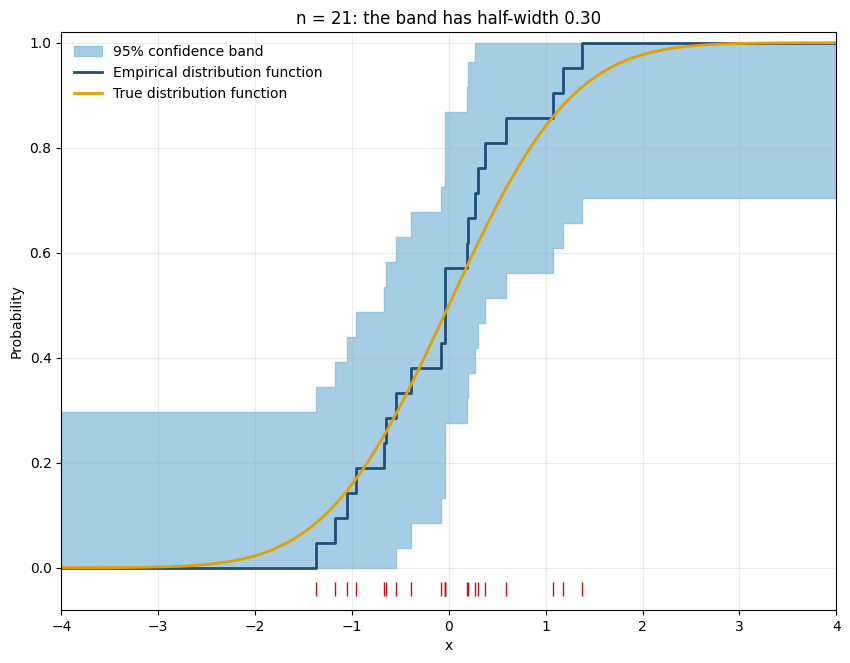

In [10]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_band(ax, sample, ALPHA)

With 21 observations the band is wide: the distribution function is known with an error of up to 0.3.

### The effect of the sample size and the level

Move the sliders to change the sample size $n$ and the level $\alpha$. The half-width of the band decreases as $1/\sqrt{n}$, and grows slowly when $\alpha$ decreases.

In [11]:
def interactive_band(n, alpha):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    plot_band(ax, np.random.default_rng(SEED).normal(size=n), alpha)
    plt.show()

interact(interactive_band,
         n=IntSlider(value=N, min=10, max=1000, step=1, description='n'),
         alpha=FloatSlider(value=ALPHA, min=0.01, max=0.2, step=0.01, description='alpha'));

interactive(children=(IntSlider(value=21, description='n', max=1000, min=10), FloatSlider(value=0.05, descript…

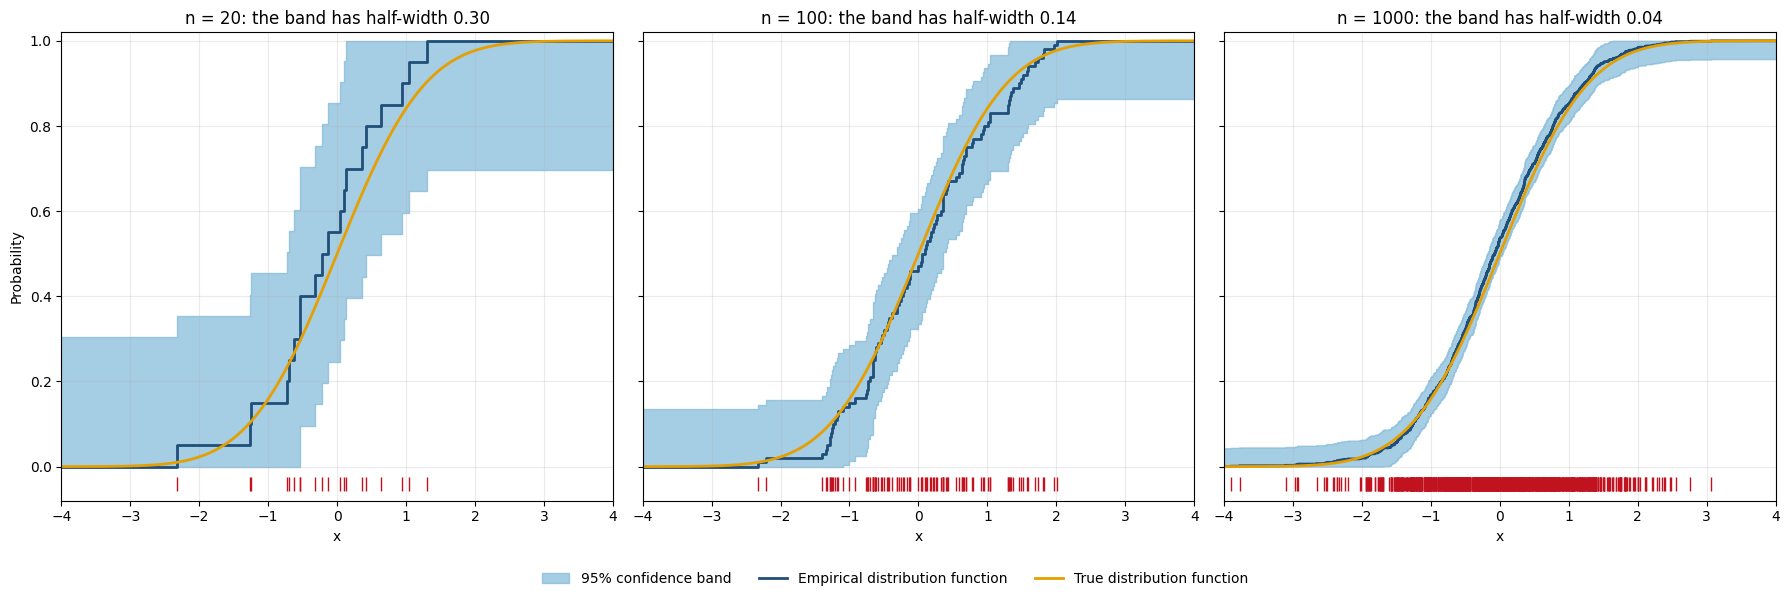

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, size in zip(axes, [20, 100, 1000]):
    plot_band(ax, np.random.default_rng(SEED).normal(size=size), ALPHA, legend=False)
for ax in axes[1:]:
    ax.set_ylabel('')
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))

## How often does the band contain the true distribution function?

The band contains $F$ exactly when $D_n=\sup_x|\hat F_n(x)-F(x)|\leq\varepsilon_n$. We simulate many samples of size 21, calculate $D_n$ for each of them, and count how many times it is at most $\varepsilon_n$. The supremum is attained at an observation, just at or just before the jump:

$$
D_n=\max_i\max\left\{\frac{i}{n}-F(x_{(i)}),\ F(x_{(i)})-\frac{i-1}{n}\right\}.
$$

In [13]:
def sup_distance(samples):
    # One sample in each row
    n = samples.shape[1]
    F = norm.cdf(np.sort(samples, axis=1))
    i = np.arange(1, n+1)
    return np.maximum(i/n - F, F - (i-1)/n).max(axis=1)

In [14]:
SAMPLES = 10000  # Number of simulations

distances = sup_distance(rng.normal(size=(SAMPLES, N)))
epsilon = dkw_epsilon(N, ALPHA)
coverage = np.mean(distances <= epsilon)

print(epsilon)
print(coverage)

0.2963620474912214
0.9628


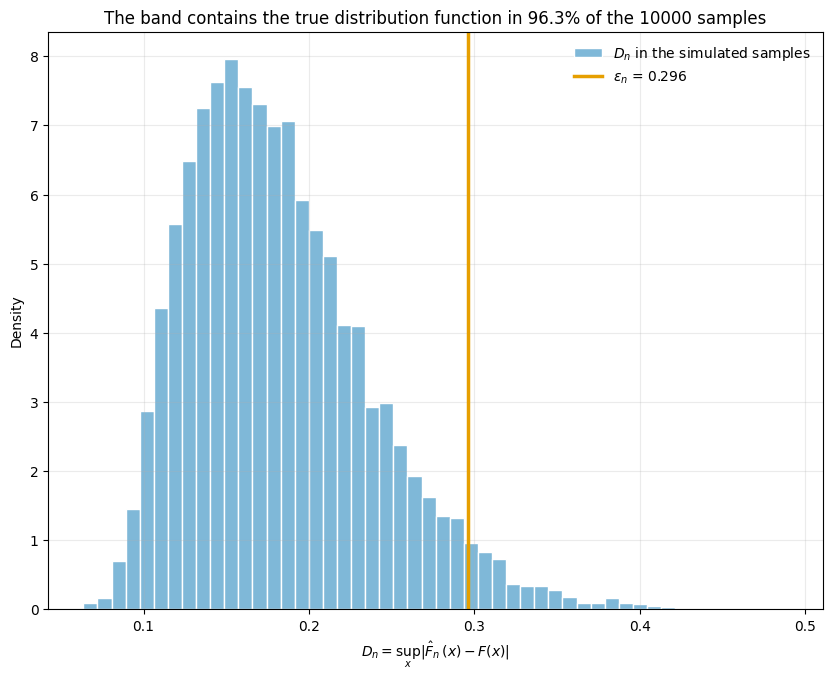

In [15]:
plt.figure(figsize=(10, 7.5))
plt.hist(distances, bins=50, density=True, color=ci_color, edgecolor='white',
         label=r'$D_n$ in the simulated samples')
plt.axvline(epsilon, color=opt_color, lw=2.5, label=rf'$\varepsilon_n$ = {epsilon:.3f}')

plt.xlabel(r'$D_n=\sup_x|\hat F_n(x)-F(x)|$')
plt.ylabel('Density')
plt.title(f'The band contains the true distribution function in {coverage:.1%} of the {SAMPLES} samples')
plt.legend(frameon=False)
plt.grid(True, alpha=0.25)

The proportion is at least $1-\alpha$, as the inequality guarantees. It is a little above it because the inequality is a bound, not an equality.